# Экспериментальная валидация MPPI

Цель эксперимента — определить области успешного восстановления автопоезда и количественно сравнить четыре алгоритма:

1. нулевое управление;
2. простой стабилизирующий регулятор;
3. MPPI только с рулением;
4. MPPI с рулением и продольным управлением.

Полная серия содержит **1920 эпизодов**: четыре коэффициента сцепления, четыре скорости, три типа возмущения, две тяжести, пять вариантов неопределённости и четыре алгоритма.

**Главный вывод.** Текущая конфигурация MPPI даёт преимущество в отдельных тяжёлых номинальных режимах, но пока не демонстрирует общего превосходства. Основная причина провалов — задержка управления 150 мс, не включённая во внутреннюю модель прогноза. Это означает, что текущий MPPI требует доработки перед заявлением о робастном преимуществе.


## План эксперимента

| Фактор | Значения |
|---|---|
| Коэффициент сцепления | 0,7; 0,4; 0,2; 0,1 |
| Начальная скорость | 10; 15; 20; 25 м/с |
| Возмущение | занос тягача; занос полуприцепа; складывание |
| Тяжесть | умеренная; тяжёлая |
| Неопределённость | номинал; ошибка модели; задержка 150 мс; измерительный шум; совместное воздействие |
| Горизонт моделирования | 5 с при шаге 0,02 с |
| Горизонт MPPI | 50 шагов, то есть 1 с |

Ошибка модели включает смещения масс, моментов инерции, боковых жёсткостей, коэффициента сцепления и геометрии. Измерительный шум добавляется к скоростям, курсовым углам, угловым скоростям и углу руля. Задержка 150 мс при шаге 20 мс моделируется линейной интерполяцией между командами с задержкой 140 и 160 мс.

### Ограничения интерпретации

**Аэродинамика не учитывается.** В динамической модели отсутствуют аэродинамическое сопротивление, боковая аэродинамическая сила, аэродинамический момент, влияние бокового ветра и изменение прижимной силы. Особенно при скоростях 20–25 м/с добавление аэродинамики могло бы изменить потерю продольной скорости, боковую динамику, время восстановления и границы области успеха. Поэтому полученные карты относятся только к реализованной механико-шинной модели без аэродинамики.

**MPPI не учитывает задержку внутри прогноза.** В сценариях `delay_150ms` и `combined` задержка добавляется после вычисления команды, между выходом регулятора и входом plant-модели. Внутренний rollout MPPI предполагает, что рассчитанная команда действует немедленно. Следовательно, эти сценарии проверяют MPPI при немоделируемой задержке исполнительного канала; сильное падение успешности нельзя переносить на MPPI с явно включённой моделью задержки или её компенсацией.

### Критерий успешного восстановления

К концу эпизода состояние должно войти в коридор и оставаться в нём:

$$
|v_y| < 0.15\,\mathrm{m/s}, \qquad |r_1|, |r_2| < 0.025\,\mathrm{rad/s}
$$

$$
|\eta| < 0.04\,\mathrm{rad}, \qquad |\alpha_2| < 0.03\,\mathrm{rad}, \qquad v_x > 2\,\mathrm{m/s}
$$

Дополнительно на всём интервале требуется `|η|<0,8 рад`, `|r1|,|r2|<1 рад/с` и конечность всех состояний.


## Загрузка данных

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

CSV_DIR = Path("csv")
results = pd.read_csv(CSV_DIR / "mppi_experiment_results.csv")
trajectories = pd.read_csv(CSV_DIR / "mppi_representative_trajectories.csv")

algorithm_order = ["zero", "stabilizer", "mppi_steering", "mppi_full"]
algorithm_labels = {
    "zero": "Нулевое управление",
    "stabilizer": "Стабилизатор",
    "mppi_steering": "MPPI руление",
    "mppi_full": "MPPI полный",
}
uncertainty_order = ["nominal", "model_error", "measurement_noise", "delay_150ms", "combined"]
assert len(results) == 1920
results.head()


,mu,speed,disturbance,severity,initial_vy,initial_r1,initial_r2,initial_eta,uncertainty,algorithm,...,integrated_error,control_energy,steering_effort,braking_effort,minimum_vx,final_vx,final_vy,final_r1,final_r2,final_eta
0,0.7,10.0,tractor_skid,moderate,0.6,0.08,0.0,0.03,nominal,zero,...,0.125436,0.000000,0.000000,0.000000,9.994787,9.994787,-0.000030,5.210000e-06,0.000135,0.000102
1,0.7,10.0,tractor_skid,moderate,0.6,0.08,0.0,0.03,nominal,stabilizer,...,0.096516,0.002120,0.002120,0.000000,9.993051,9.993051,-0.000006,-1.900000e-07,0.000030,0.000022
2,0.7,10.0,tractor_skid,moderate,0.6,0.08,0.0,0.03,nominal,mppi_steering,...,0.107384,0.183202,0.183202,0.000000,9.992744,9.992744,0.020826,6.238490e-03,-0.002925,-0.003018
3,0.7,10.0,tractor_skid,moderate,0.6,0.08,0.0,0.03,nominal,mppi_full,...,0.103591,3.074623,0.160225,2.206401,8.877031,8.890322,-0.002987,1.503110e-03,0.000715,0.001255
4,0.7,10.0,tractor_skid,moderate,0.6,0.08,0.0,0.03,model_error,zero,...,0.125436,0.000000,0.000000,0.000000,9.994787,9.994787,-0.000030,5.210000e-06,0.000135,0.000102


## Общая результативность

In [2]:
overall = (
    results.groupby("algorithm", as_index=False)
    .agg(
        success_rate=("success", "mean"),
        mean_recovery_time=("recovery_time", "mean"),
        mean_peak_eta=("peak_abs_eta", "mean"),
        mean_integrated_error=("integrated_error", "mean"),
        mean_speed_loss=("speed", lambda x: np.nan),
    )
    .set_index("algorithm")
    .reindex(algorithm_order)
)
overall["mean_speed_loss"] = (
    results.assign(speed_loss=results["speed"] - results["final_vx"])
    .groupby("algorithm")["speed_loss"].mean()
    .reindex(algorithm_order)
)
overall.index = [algorithm_labels[index] for index in overall.index]
overall_display = overall.copy()
overall_display["success_rate"] = 100 * overall_display["success_rate"]
overall_display = overall_display.rename(columns={"success_rate": "success_rate_percent"})
overall_display.round({
    "success_rate_percent": 1,
    "mean_recovery_time": 2,
    "mean_peak_eta": 3,
    "mean_integrated_error": 2,
    "mean_speed_loss": 2,
})


,success_rate_percent,mean_recovery_time,mean_peak_eta,mean_integrated_error,mean_speed_loss
Нулевое управление,85.4,2.19,0.241,18.42,0.36
Стабилизатор,76.5,2.07,0.233,34.24,1.02
MPPI руление,50.2,1.89,0.222,25.27,0.67
MPPI полный,54.2,1.95,0.215,46.06,1.89


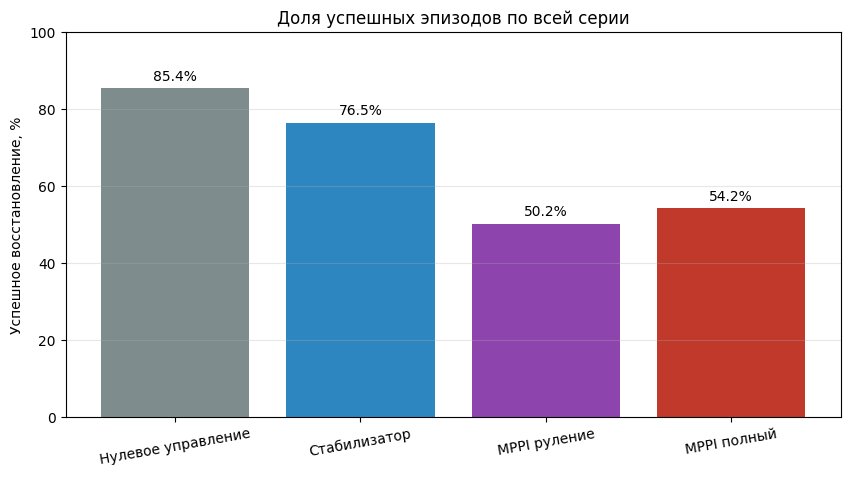

In [3]:
success = results.groupby("algorithm")["success"].mean().reindex(algorithm_order)
fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar([algorithm_labels[x] for x in success.index], 100 * success.values,
              color=["#7f8c8d", "#2e86c1", "#8e44ad", "#c0392b"])
ax.set_ylabel("Успешное восстановление, %")
ax.set_ylim(0, 100)
ax.set_title("Доля успешных эпизодов по всей серии")
ax.grid(axis="y", alpha=0.3)
for bar, value in zip(bars, success.values):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 2,
            f"{100*value:.1f}%", ha="center")
plt.xticks(rotation=10)
plt.show()


По всей серии нулевое управление успешно в 85,4% эпизодов, стабилизатор — в 76,5%, MPPI с продольным управлением — в 54,2%, MPPI только с рулением — в 50,2%. Высокий результат нулевого управления объясняется собственной демпфирующей динамикой модели: большинство умеренных начальных возмущений затухает без вмешательства.

MPPI уменьшает средний пик угла складывания, но платит за это более низкой робастностью и потерей продольной скорости. Поэтому корректная формулировка результата — **локальное динамическое преимущество без общего преимущества по надёжности**.


## Карта областей успешного восстановления

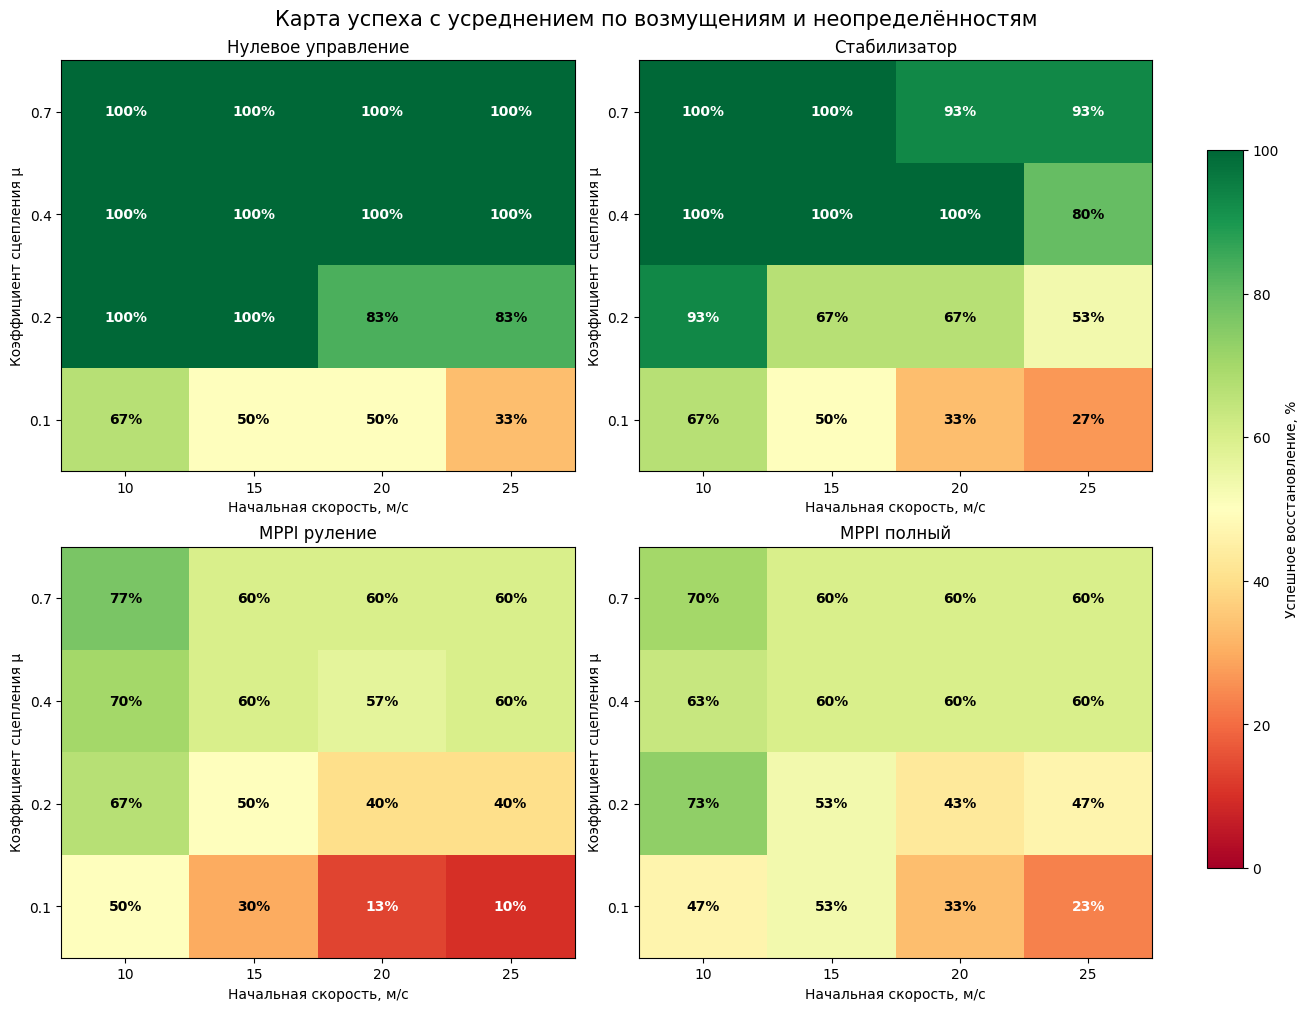

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(13, 10), constrained_layout=True)
for ax, algorithm in zip(axes.flat, algorithm_order):
    matrix = (
        results[results["algorithm"] == algorithm]
        .pivot_table(index="mu", columns="speed", values="success", aggfunc="mean")
        .sort_index(ascending=False)
    )
    image = ax.imshow(100 * matrix.values, vmin=0, vmax=100, cmap="RdYlGn", aspect="auto")
    ax.set_xticks(range(len(matrix.columns)), [f"{x:g}" for x in matrix.columns])
    ax.set_yticks(range(len(matrix.index)), [f"{x:g}" for x in matrix.index])
    ax.set_xlabel("Начальная скорость, м/с")
    ax.set_ylabel("Коэффициент сцепления μ")
    ax.set_title(algorithm_labels[algorithm])
    for row in range(matrix.shape[0]):
        for column in range(matrix.shape[1]):
            value = 100 * matrix.iloc[row, column]
            ax.text(column, row, f"{value:.0f}%", ha="center", va="center",
                    color="black" if 25 < value < 85 else "white", fontweight="bold")
fig.colorbar(image, ax=axes, label="Успешное восстановление, %", shrink=0.8)
fig.suptitle("Карта успеха с усреднением по возмущениям и неопределённостям", fontsize=15)
plt.show()


Карта показывает ожидаемое сужение области восстановления при снижении `μ` и увеличении скорости. На `μ=0,4–0,7` пассивная модель восстанавливается во всех эпизодах нулевого управления. При `μ=0,1` преимущество продольного управления проявляется относительно MPPI только с рулением, однако простой регулятор и нулевое управление всё ещё дают более высокую суммарную долю успеха.


## Робастность к ошибкам, задержке и шуму

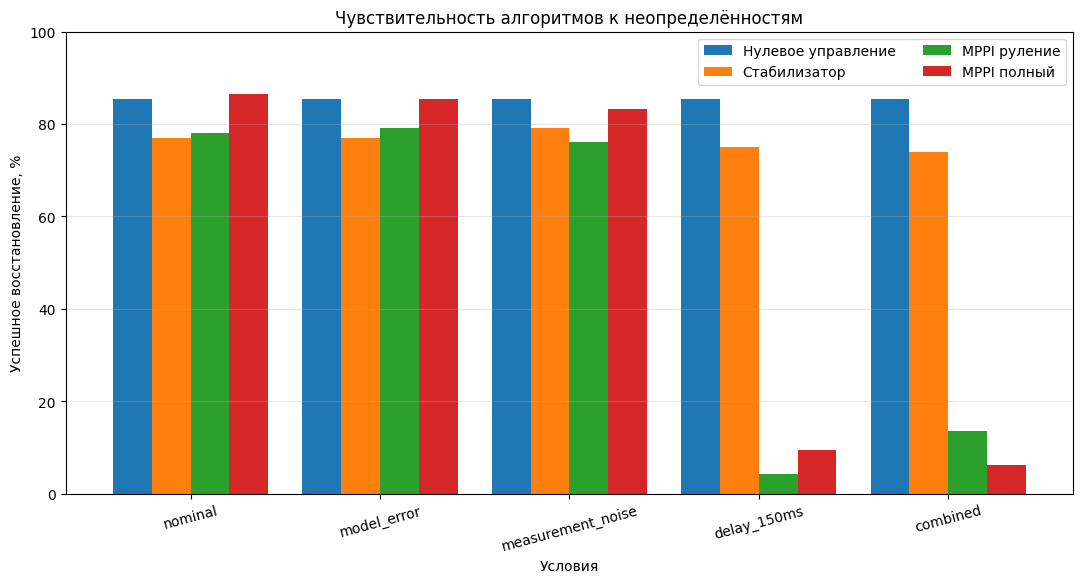

algorithm,zero,stabilizer,mppi_steering,mppi_full
uncertainty,,,,
nominal,85.4,77.1,78.1,86.5
model_error,85.4,77.1,79.2,85.4
measurement_noise,85.4,79.2,76.0,83.3
delay_150ms,85.4,75.0,4.2,9.4
combined,85.4,74.0,13.5,6.2


In [5]:
robustness = (
    results.pivot_table(index="uncertainty", columns="algorithm", values="success", aggfunc="mean")
    .reindex(uncertainty_order)[algorithm_order]
)
ax = 100 * robustness.rename(columns=algorithm_labels)
ax.plot(kind="bar", figsize=(13, 6), width=0.82)
plt.ylabel("Успешное восстановление, %")
plt.xlabel("Условия")
plt.title("Чувствительность алгоритмов к неопределённостям")
plt.xticks(rotation=15)
plt.ylim(0, 100)
plt.grid(axis="y", alpha=0.3)
plt.legend(ncol=2)
plt.show()

(100 * robustness).round(1)


Ошибка параметров и измерительный шум сами по себе не разрушают MPPI: успешность полного MPPI составляет соответственно 85,4% и 83,3%. В номинальном режиме полный MPPI достигает 86,5%. Критический фактор — задержка 150 мс: успешность падает до 9,4% для полного MPPI и до 4,2% для MPPI с рулением. При совместном воздействии значения составляют 6,3% и 13,5%.

Нулевое управление не зависит от этих факторов, а простой регулятор сохраняет 63,5% успеха при совместном воздействии. Для MPPI необходимо включить задержку в модель прогноза либо использовать оценивание состояния и компенсацию задержки.


## Зависимость от вида начального возмущения

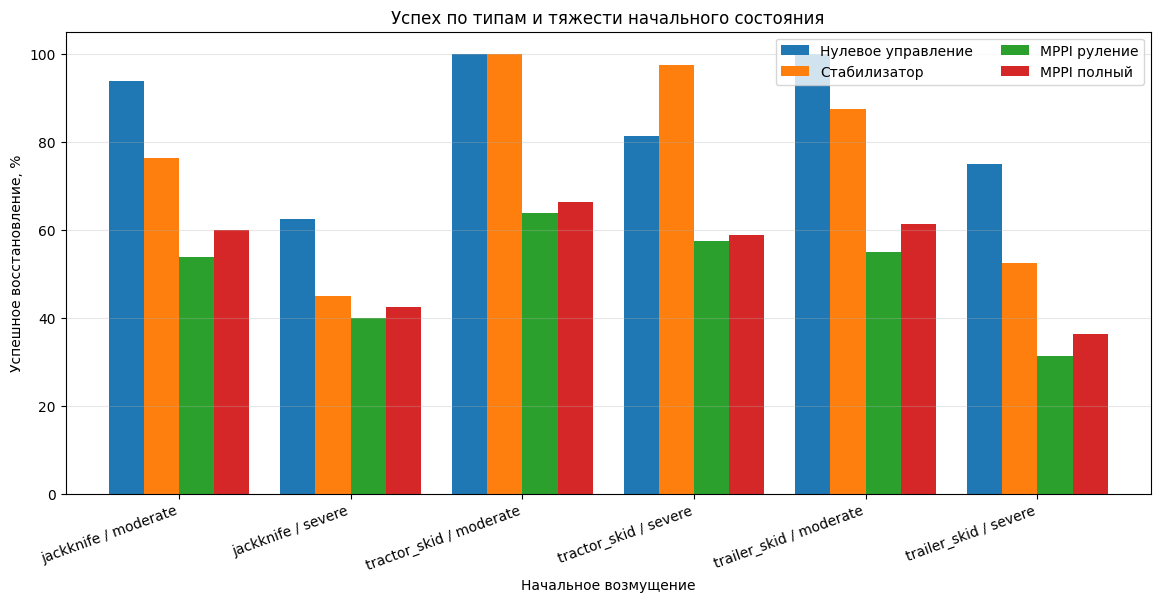

In [6]:
by_disturbance = (
    results.assign(case=results["disturbance"] + " / " + results["severity"])
    .pivot_table(index="case", columns="algorithm", values="success", aggfunc="mean")
    [algorithm_order]
)
(100 * by_disturbance.rename(columns=algorithm_labels)).plot(
    kind="bar", figsize=(14, 6), width=0.82
)
plt.ylabel("Успешное восстановление, %")
plt.xlabel("Начальное возмущение")
plt.title("Успех по типам и тяжести начального состояния")
plt.xticks(rotation=20, ha="right")
plt.ylim(0, 105)
plt.grid(axis="y", alpha=0.3)
plt.legend(ncol=2)
plt.show()


Все алгоритмы уверенно справляются с умеренным заносом тягача. Самыми сложными являются тяжёлое складывание и тяжёлый занос полуприцепа. Именно в этих режимах продольное управление уменьшает пиковый угол складывания, но текущая настройка MPPI не превращает это преимущество в более высокую общую вероятность успеха.


## Количественное преимущество в тяжёлом номинальном складывании

In [7]:
representative = results[
    np.isclose(results["mu"], 0.4)
    & np.isclose(results["speed"], 15.0)
    & (results["disturbance"] == "jackknife")
    & (results["severity"] == "severe")
    & (results["uncertainty"] == "nominal")
].set_index("algorithm").reindex(algorithm_order)

table = representative[["success", "recovery_time", "peak_abs_eta", "integrated_error", "final_vx"]].copy()
table.index = [algorithm_labels[index] for index in table.index]
table.round({
    "recovery_time": 2,
    "peak_abs_eta": 3,
    "integrated_error": 2,
    "final_vx": 2,
})


,success,recovery_time,peak_abs_eta,integrated_error,final_vx
Нулевое управление,1,2.70,0.507,17.47,14.54
Стабилизатор,1,2.86,0.474,14.78,14.28
MPPI руление,1,2.56,0.474,15.53,14.13
MPPI полный,1,2.28,0.467,14.37,14.34


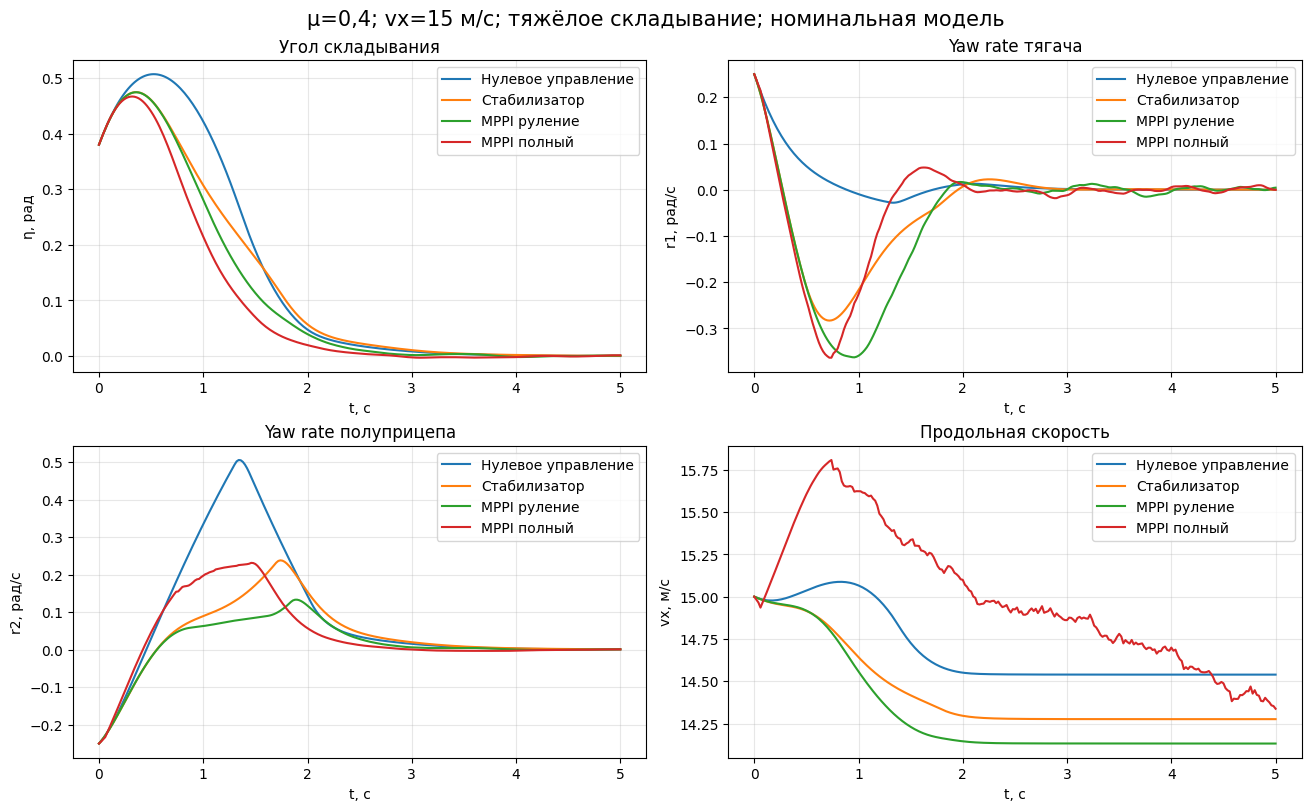

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8), constrained_layout=True)
for algorithm in algorithm_order:
    frame = trajectories[trajectories["algorithm"] == algorithm]
    label = algorithm_labels[algorithm]
    axes[0, 0].plot(frame["t"], frame["eta"], label=label)
    axes[0, 1].plot(frame["t"], frame["r1"], label=label)
    axes[1, 0].plot(frame["t"], frame["r2"], label=label)
    axes[1, 1].plot(frame["t"], frame["vx"], label=label)
for ax, title, ylabel in zip(
    axes.flat,
    ["Угол складывания", "Yaw rate тягача", "Yaw rate полуприцепа", "Продольная скорость"],
    ["η, рад", "r1, рад/с", "r2, рад/с", "vx, м/с"],
):
    ax.set_title(title)
    ax.set_xlabel("t, с")
    ax.set_ylabel(ylabel)
    ax.grid(True, alpha=0.3)
    ax.legend()
fig.suptitle("μ=0,4; vx=15 м/с; тяжёлое складывание; номинальная модель", fontsize=15)
plt.show()


В выбранном тяжёлом номинальном сценарии полный MPPI показывает реальное преимущество относительно нулевого управления:

- время восстановления уменьшается с 2,70 до 2,28 с — на **15,6%**;
- максимальный угол складывания уменьшается с 0,507 до 0,467 рад — на **7,9%**;
- интегральная ошибка уменьшается с 17,47 до 14,37 — на **17,8%**.

MPPI только с рулением также ускоряет восстановление до 2,56 с, но полный MPPI даёт лучший результат по всем трём динамическим показателям ценой дополнительной потери скорости.


## Цена управления

In [10]:
cost = (
    results.assign(speed_loss=results["speed"] - results["final_vx"])
    .groupby("algorithm")
    .agg(
        steering_effort=("steering_effort", "mean"),
        braking_effort=("braking_effort", "mean"),
        speed_loss=("speed_loss", "mean"),
        peak_eta=("peak_abs_eta", "mean"),
    )
    .reindex(algorithm_order)
)
cost.index = [algorithm_labels[index] for index in cost.index]
cost.round(3)


,steering_effort,braking_effort,speed_loss,peak_eta
Нулевое управление,0.000,0.000,0.359,0.241
Стабилизатор,0.047,0.000,1.015,0.233
MPPI руление,0.454,0.000,0.667,0.222
MPPI полный,0.529,4.854,1.891,0.215


## Итог и направления доработки

1. **Текущий MPPI не имеет общего преимущества по вероятности восстановления.** Это нужно фиксировать как результат валидации.
2. **Преимущество подтверждено локально** для тяжёлого номинального складывания: быстрее восстановление, меньше пик `η` и ниже интегральная ошибка.
3. **Главный дефект — задержка.** Следующий эксперимент должен включать задержку в rollout, прогноз состояния на момент фактического применения команды или Smith predictor.
4. **Продольный канал требует отдельной настройки.** Он уменьшает угол складывания при низком сцеплении, но средняя потеря скорости существенно выше.
5. **Пассивная устойчивость модели очень сильна.** Для проверки контроллера следует добавить внешние возмущающие силы, дорожную кривизну и параметрические режимы около границы устойчивости, а не только начальное отклонение.
6. **Аэродинамика отсутствует.** Результаты, особенно для 20–25 м/с, необходимо перепроверить после добавления продольного сопротивления, боковой аэродинамической силы, момента и бокового ветра.

## Воспроизводимость

```bash
cmake -S truck_model_cpp -B truck_model_cpp/build -DCMAKE_BUILD_TYPE=Release
cmake --build truck_model_cpp/build -j 4
truck_model_cpp/build/validate_mppi truck_model_cpp/experements/csv
```

Runner: `simulation/validate_mppi.cpp`  
Полные результаты: `csv/mppi_experiment_results.csv`  
Представительные траектории: `csv/mppi_representative_trajectories.csv`
